# Streaming

In [ ]:
import os
import pyrealsense2 as rs
import numpy as np
import cv2

In [ ]:
# config classes
pipeline = rs.pipeline()
config = rs.config()

# Get device product line for setting a supporting resolution
pipeline_wrapper = rs.pipeline_wrapper(pipeline)
pipeline_profile = config.resolve(pipeline_wrapper)

device = pipeline_profile.get_device()
device_product_line = str(device.get_info(rs.camera_info.product_line))

found_rgb = False
for s in device.sensors:
    if s.get_info(rs.camera_info.name) == "RGB Camera":
        found_rgb = True
        break
if not found_rgb:
    print("The demo requires Depth camera with Color sensor")
    exit(0)


In [ ]:
# depth
config.enable_stream(
    stream_type=rs.stream.depth, width=640, height=480, format=rs.format.z16, framerate=60
)
# color
config.enable_stream(
    stream_type=rs.stream.color, width=640, height=480, format=rs.format.bgr8, framerate=60
)
# infra
# config.enable_stream(
#     stream_type=rs.stream.infrared, width=640, height=480, format=rs.format.bgr8 , framerate=60
# )

# is selected config (for specific pipeline) valid
if config.can_resolve(pipeline):
    print('config OK')
else:
    print('baj van')

In [ ]:
# Start streaming
pipeline.start(config)

try:
    while True:

        # Wait for a coherent pair of frames: depth and color
        frames = pipeline.wait_for_frames()
        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()
        # infra_frame = frames.get_infrared_frame()

        if not depth_frame or not color_frame:
            continue

        # Convert images to numpy arrays
        depth_image = np.asanyarray(depth_frame.get_data())
        color_image = np.asanyarray(color_frame.get_data())
        # infra_image = np.asanyarray(infra_frame.get_data())

        # Apply colormap on depth image (image must be converted to 8-bit per pixel first)
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )

        depth_colormap_dim = depth_colormap.shape
        color_colormap_dim = color_image.shape

        # If depth and color resolutions are different, resize color image to match depth image for display
        if depth_colormap_dim != color_colormap_dim:
            resized_color_image = cv2.resize(
                color_image,
                dsize=(depth_colormap_dim[1], depth_colormap_dim[0]),
                interpolation=cv2.INTER_AREA,
            )
            images = np.hstack((resized_color_image, depth_colormap))
        else:
            images = np.hstack((color_image, depth_colormap))
            # images = np.hstack((color_image, depth_colormap, infra_image))

        # Show images
        cv2.namedWindow("RealSense", cv2.WINDOW_AUTOSIZE)
        cv2.imshow("RealSense", images)

        # press q to exit without crash
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    cv2.destroyAllWindows()

finally:

    # Stop streaming
    pipeline.stop()


In [ ]:
infra_image.shape, color_image.shape, depth_image.shape

In [ ]:
ord('e')

# Recording

In [1]:
import os
import time
import cv2
import numpy as np
import pyrealsense2 as rs
from util import resolution_presets

In [2]:
# set recording name & parameters
recording_name = "w2"
recording_file_name = os.path.join("data", recording_name, recording_name + ".db3")
preset = resolution_presets["640x360@90"]  # '848x480@60', '640x360@90', '480x270@90'

RECORDING_DURATION = 65  # seconds


if not os.path.isdir(os.path.join("data", recording_name)):
    os.mkdir(os.path.join("data", recording_name))

# config classes
pipeline = rs.pipeline()
config = rs.config()

# depth
config.enable_stream(
    stream_type=rs.stream.depth,
    width=preset["width"],
    height=preset["height"],
    format=rs.format.z16,
    framerate=preset["fps"],
)
# color
config.enable_stream(
    stream_type=rs.stream.color,
    width=preset["width"],
    height=preset["height"],
    format=rs.format.bgr8,
    framerate=preset["fps"],
)
# enable recording
config.enable_record_to_file(file_name=recording_file_name)
queue = rs.frame_queue(capacity=200, keep_frames=True)

# is selected config (for specific pipeline) valid
if config.can_resolve(pipeline):
    print("config OK")
else:
    print("baj van")

config OK


In [3]:
pipeline.start(config, queue)

start_time = time.time()
current_time = 0

try:
    while current_time - start_time < RECORDING_DURATION:

        frames = queue.wait_for_frame()
        frames = frames.as_frameset()

        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()

        if not depth_frame or not color_frame:
            continue

        depth_image = np.asanyarray(depth_frame.get_data())
        color_image = np.asanyarray(color_frame.get_data())

        # Apply colormap on depth image (image must be converted to 8-bit per pixel first)
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )

        depth_colormap_dim = depth_colormap.shape
        color_colormap_dim = color_image.shape

        display_images = np.hstack((color_image, depth_colormap))

        current_time = time.time()

        cv2.namedWindow("RealSense", cv2.WINDOW_AUTOSIZE)
        cv2.imshow("RealSense", display_images)

        # press q to exit without crash
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    cv2.destroyAllWindows()

finally:
    pipeline.stop()

## Calibration image

In [3]:
import pyrealsense2 as rs
import numpy as np

calibration_image_out_file_name = os.path.join("data", recording_name, "calibration_image.png")

pipeline = rs.pipeline()
config = rs.config()

config.enable_stream(
    stream_type=rs.stream.color,
    width=preset["width"],
    height=preset["height"],
    format=rs.format.bgr8,
    framerate=preset["fps"],
)
profile = pipeline.start(config)
start_time = time.time()
current_time = 0

try:
    while current_time - start_time < 5:

        frames = pipeline.wait_for_frames()

        color_frame = frames.get_color_frame()

        if not color_frame:
            continue

        color_image = np.asanyarray(color_frame.get_data())

        current_time = time.time()
        if current_time-start_time > 2:
            cv2.imwrite(calibration_image_out_file_name, color_image)
            break


        # press q to exit without crash
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    pipeline.stop()

In [ ]:
current_time-start_time

# Playback from file

In [ ]:
import pyrealsense2 as rs
import numpy as np
import cv2
import os

In [ ]:
recording_name = "p1"
recording_file_name = os.path.join("data", recording_name, recording_name + ".db3")
if not os.path.exists(recording_file_name):
    raise FileNotFoundError(f'File {recording_file_name} does not exits')

pipeline = rs.pipeline()
config = rs.config()

config.enable_device_from_file(file_name=recording_file_name, repeat_playback=False)

config.enable_stream(
    stream_type=rs.stream.depth, width=848, height=480, format=rs.format.z16, framerate=60
)
config.enable_stream(
    stream_type=rs.stream.color, width=848, height=480, format=rs.format.bgr8, framerate=60
)
if config.can_resolve(pipeline):
    print('config OK')

In [ ]:
# Start streaming from file
pipeline.start(config)


# Create colorizer object
colorizer = rs.colorizer()
frames = None

success = True
frame_meta = []

while success:

    success, frames = pipeline.try_wait_for_frames(timeout_ms=500)

    if frames:

        depth_frame = frames.get_depth_frame()
        # Colorize depth frame to jet colormap
        depth_color_frame = colorizer.colorize(depth_frame)
        # Convert depth_frame to numpy array to render image in opencv
        depth_color_image = np.asanyarray(depth_color_frame.get_data())

        color_frame = frames.get_color_frame()
        color_image = np.asanyarray(color_frame.get_data())

        images = np.hstack((color_image, depth_color_image))

        cv2.imshow("Playback", images)
    key = cv2.waitKey(1)
    # if pressed escape exit program
    if key == 27 or key == ord("q"):
        cv2.destroyAllWindows()
        break
    
cv2.destroyAllWindows()
pipeline.stop()

# Align, save color & depth

.db3 --> .mp4 (color), .raw (depth), .bin (timestamps), .json (metadata)

In [1]:
import os
import json
import subprocess
import numpy as np
import pyrealsense2 as rs
import glob
from util import create_ffmpeg_command
%matplotlib ipympl

recording_name = "w1"
out_folder = os.path.join("data", recording_name)

if os.path.isdir(out_folder):
    recording_file_name = os.path.join(out_folder, recording_name + ".db3")
    if not os.path.exists(recording_file_name):
        raise FileNotFoundError(f'File {recording_file_name} does not exist')
    out_filename_color = os.path.join(out_folder,recording_name+"_color.mp4")
    out_filename_depth = os.path.join(out_folder, recording_name+"_depth.mkv")
    out_filename_timestamps = os.path.join(out_folder, recording_name+"_timestamps.bin")
    out_filename_metadata = os.path.join(out_folder, recording_name+"_metadata.json")
else:
    raise FileNotFoundError(f"Folder {recording_name} does not exist")

In [2]:
# config
pipeline = rs.pipeline()
config = rs.config()
config.enable_device_from_file(recording_file_name, repeat_playback=False)

profile = pipeline.start(config)

# Get depth intrinsics
depth_profile = profile.get_stream(rs.stream.depth)
depth_intrinsics = depth_profile.as_video_stream_profile().get_intrinsics()

# Get color intrinsics
color_profile = profile.get_stream(rs.stream.color)
color_intrinsics = color_profile.as_video_stream_profile().get_intrinsics()

playback = profile.get_device().as_playback()
playback.set_real_time(False)

# align_to=rs.stream.color/infra... -> aligns depth to other
# align_to=RS2_STREAM_DEPTH -> align other stream to depth
align = rs.align(align_to=rs.stream.color)

depth_sensor = profile.get_device().first_depth_sensor()
depth_scale = depth_sensor.get_depth_scale()

# filters
threshold = rs.threshold_filter(min_dist=0.05, max_dist=10.0)
depth_to_disparity = rs.disparity_transform(True)
spatial = rs.spatial_filter()
spatial.set_option(rs.option.filter_magnitude, 2)
spatial.set_option(rs.option.filter_smooth_alpha, 0.5)
spatial.set_option(rs.option.filter_smooth_delta, 20)
temporal = rs.temporal_filter()
temporal.set_option(rs.option.filter_smooth_alpha, 0.7)
temporal.set_option(rs.option.filter_smooth_delta, 15)
temporal.set_option(rs.option.holes_fill, 0)
disparity_to_depth = rs.disparity_transform(False)

ffmpeg_color = create_ffmpeg_command(
    width=color_intrinsics.width,
    height=color_intrinsics.height,
    fps=color_profile.fps(),
    encoder="h264_qsv",
    out_filename=out_filename_color,
)
video_color = subprocess.Popen(ffmpeg_color, stdin=subprocess.PIPE)

ffmpeg_depth = [
    "ffmpeg",
    "-y",
    "-f",
    "rawvideo",
    "-pix_fmt",
    "gray16le",
    "-s",
    f"{color_intrinsics.width}x{color_intrinsics.height}",
    "-r",
    str(color_profile.fps()),
    "-i",
    "-",
    "-c:v",
    "ffv1",
    out_filename_depth,
]
video_depth = subprocess.Popen(ffmpeg_depth, stdin=subprocess.PIPE)


# output files
timestamps_out = open(out_filename_timestamps, "wb", buffering=1024 * 1024)

frame_count = 0

print(f"Input:  {recording_file_name}\n")
print("Converting...")

try:
    while True:
        try:
            frames = pipeline.wait_for_frames()
        except RuntimeError:
            break

        # Align depth to the color camera
        # NOTE: later only the color intrinsics are needed
        aligned_frames = align.process(frames)
        color_frame = aligned_frames.get_color_frame()
        depth_frame = aligned_frames.get_depth_frame()

        if not color_frame or not depth_frame:
            continue

        color_image = np.asanyarray(color_frame.get_data())
        # depth_image = np.asanyarray(depth.get_data())

        filtered = threshold.process(depth_frame)
        filtered = depth_to_disparity.process(filtered)
        filtered = spatial.process(filtered)
        filtered = temporal.process(filtered)
        filtered = disparity_to_depth.process(filtered)
        filtered = filtered.as_depth_frame()
        depth_image = np.asanyarray(filtered.get_data())

        video_color.stdin.write(color_image.tobytes())
        video_depth.stdin.write(depth_image.tobytes())

        # TODO: maybe write the ts of both frames?
        timestamp = frames.get_timestamp()

        timestamps_out.write(np.float64(timestamp).tobytes())

        frame_count += 1

        if frame_count % 60 == 0:
            print(f"\rFrame: {frame_count}", end="", flush=True)

finally:

    video_color.stdin.close()
    video_color.wait()

    video_depth.stdin.close()
    video_depth.wait()

    timestamps_out.close()

    pipeline.stop()

metadata = {
    "frames": frame_count,
    "width": color_intrinsics.width,
    "height": color_intrinsics.height,
    "fps": color_profile.fps(),
    "color": out_filename_color,
    "depth": out_filename_depth,
    "depth_format": "uint16",
    "depth_alignment": "depth_to_color",
    "depth_scale_meters": depth_scale,
    "timestamps": out_filename_timestamps,
    "timestamp_unit": "milliseconds",
    "depth_intrinsics": {
        "width": depth_intrinsics.width,
        "height": depth_intrinsics.height,
        "ppx": depth_intrinsics.ppx,
        "ppy": depth_intrinsics.ppy,
        "fx": depth_intrinsics.fx,
        "fy": depth_intrinsics.fy,
        "model": str(depth_intrinsics.model),
        "coeffs": depth_intrinsics.coeffs,
    },
    "color_intrinsics": {
        "width": color_intrinsics.width,
        "height": color_intrinsics.height,
        "ppx": color_intrinsics.ppx,
        "ppy": color_intrinsics.ppy,
        "fx": color_intrinsics.fx,
        "fy": color_intrinsics.fy,
        "model": str(color_intrinsics.model),
        "coeffs": color_intrinsics.coeffs,
    },
}

with open(out_filename_metadata, "w") as f:
    json.dump(metadata, f, indent=2)

print("\n\nDone.")
print(f"Frames: {frame_count}")
print(f"Color:  {out_filename_color}")
print(f"Depth:  {out_filename_depth}")
print(f"Timestamps:  {out_filename_timestamps}")
print(f"Metadata:  {out_filename_metadata}")

Input:  data\w1\w1.db3

Converting...
Frame: 3840

Done.
Frames: 3860
Color:  data\w1\w1_color.mp4
Depth:  data\w1\w1_depth.mkv
Timestamps:  data\w1\w1_timestamps.bin
Metadata:  data\w1\w1_metadata.json


# Get 2D keypoints

mp4 --> 2D keypoints (camera frame)

In [3]:
import os
import sys
import cv2
import time
import json
import importlib
import numpy as np
from util import *
from pathlib import Path
import onnxruntime as ort
from IPython.display import display, clear_output
rtmlib_module = importlib.import_module("rtmlib")

device = 'cuda'
backend = 'onnxruntime'
openpose_skeleton = False

site_packages = Path(sys.prefix) / "Lib" / "site-packages"
cuda_bin = site_packages / "nvidia" / "cu13" / "bin" / "x86_64"
cudnn_bin = site_packages / "nvidia" / "cudnn" / "bin"

os.add_dll_directory(str(cuda_bin))
os.add_dll_directory(str(cudnn_bin))
ort.preload_dlls(
    cuda=True,
    cudnn=True,
    directory=str(cuda_bin),
)

print("ORT providers:", ort.get_available_providers())
custom = Custom(
    det_class="YOLOX",  #'RTMDet',
    det="https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/yolox_nano_8xb8-300e_humanart-40f6f0d0.zip",
    det_input_size=(416,416),
    pose_class="RTMPose",
    pose='https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/rtmpose-x_simcc-body7_pt-body7-halpe26_700e-384x288-7fb6e239_20230606.zip',
    pose_input_size=(288,384),
    backend=backend,
    device=device,
)

# custom = Custom(
#     det_class="YOLOX",  #'RTMDet',
#     det="https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/yolox_nano_8xb8-300e_humanart-40f6f0d0.zip",
#     det_input_size=(416,416),
#     pose_class="RTMPose",
#     pose="https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/rtmpose-m_simcc-body7_pt-body7-halpe26_700e-256x192-4d3e73dd_20230605.zip",
#     pose_input_size=(192, 256),
#     backend=backend,
#     device=device,
# )

ORT providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
load C:\Users\unger\.cache\rtmlib\hub\checkpoints\yolox_nano_8xb8-300e_humanart-40f6f0d0.onnx with onnxruntime backend
load C:\Users\unger\.cache\rtmlib\hub\checkpoints\rtmpose-x_simcc-body7_pt-body7-halpe26_700e-384x288-7fb6e239_20230606.onnx with onnxruntime backend


In [4]:
recording_name = "w1"
input_video_filename = os.path.join("data", recording_name, recording_name+"_color.mp4")
filename_metadata = os.path.join('data', recording_name, recording_name+'_metadata.json')
out_filename_keypoints_2d = os.path.join("data", recording_name, recording_name+"_keypoints_2d")
if not os.path.exists(input_video_filename):
    raise FileNotFoundError(f'File {input_video_filename} does not exist')
if not os.path.exists(filename_metadata):
    raise FileNotFoundError(f'File {filename_metadata} does not exist')

with open(filename_metadata) as f:
    metadata = json.load(f)

print(f"processing: {input_video_filename}")

# containers to store the results in
keypoints_2d = []
mid_shoulder = []

cap = cv2.VideoCapture(input_video_filename)
if cap.isOpened() == False:
    raise FileNotFoundError(f"Error opening video file: {input_video_filename}")

total_num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
processed_num_frames = 0
start_time = time.time_ns()
ppl = []

from util import hex_to_bgr
colors = [hex_to_bgr("#6AE611"),hex_to_bgr("#B82EC7"), hex_to_bgr("#F1791D")]

while cap.isOpened():
    ret, frame = cap.read()

    if ret == True:
        processed_num_frames += 1

        # rotate frame to portrait mode so pose estimation works
        frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)

        width = frame.shape[1]
        height = frame.shape[0]
        
        POI = np.array([width / 2, height / 2])

        # inference
        keypoints, scores = custom(frame)
        print(keypoints.shape)
        num_ppl = keypoints.shape[0]
        ppl.append(num_ppl)

        #TODO: add tracking or ROI
        # store results (frames * kpt * (x,y)), remove multiperson cases
        if keypoints.ndim >2:

            # distance_to_poi = lambda person: np.linalg.norm(POI - (person[19, :] + person[18, :]) / 2.0)
            # detected_persons = sorted(keypoints,key=distance_to_poi)
            # for person_idx, keypoints in enumerate(detected_persons):
            #     for kpt in keypoints[:, :]:
            #         cv2.circle(frame, (int(kpt[0]), int(kpt[1])), 3, colors[person_idx], 2)
            # keypoints = detected_persons[0]
            keypoints = keypoints[0, :, :]
                

        keypoints = np.squeeze(keypoints)

        keypoints_2d.append(keypoints)

        cv2.circle(frame, (int(POI[0]), int(POI[1])),3,(255,0,0),2)
        # cv2.circle(frame,(int(POI[1]), int(POI[0])),3,(255,0,0),2)
        for kpt in keypoints[:, :]:
            cv2.circle(frame, (int(kpt[0]), int(kpt[1])), 3, (0, 255, 0), 2)

        cv2.imshow("Image", cv2.resize(frame, (int(width), int(height))))

        # display how much time elapsed/is left
        clear_output(wait=True)
        end_time = time.time_ns()
        elapsed_time = (end_time - start_time) / 1000000000

        fps = round(processed_num_frames / elapsed_time, 2)
        done_ratio = processed_num_frames / total_num_frames
        expected_duration_min = elapsed_time / (done_ratio * 60)

        display(
            f"exp_duration: {round(expected_duration_min,2)} minutes, elapsed: {round(elapsed_time/60,2)} minutes"
        )
        display(f"done: {round(done_ratio*100,2)}%, fps: {fps}")

        # Press Q on keyboard to exit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    else:
        break
cap.release()
cv2.destroyAllWindows()

keypoints_2d = np.asarray(keypoints_2d)

# add mid_shoulder (between left and right)
left_shoulder = keypoints_2d[:,6,:]
right_shoulder = keypoints_2d[:,5,:]
mid_shoulder = np.nanmean([left_shoulder, right_shoulder], axis=0)
mid_shoulder = np.expand_dims(np.array(mid_shoulder), axis=1)
keypoints_2d = np.hstack((keypoints_2d, mid_shoulder))

np.save(out_filename_keypoints_2d, keypoints_2d)

print(f"shape of keypoints_2d:  {keypoints_2d.shape}")

'exp_duration: 4.42 minutes, elapsed: 4.42 minutes'

'done: 100.0%, fps: 14.55'

shape of keypoints_2d:  (3860, 27, 2)


# Filter 2D keypoints

In [5]:
import numpy as np
import os
import json
import matplotlib.pyplot as plt
%matplotlib ipympl
from util import *

recording_name = "w1"
keypoints_2d = np.load(os.path.join('data',recording_name, recording_name+'_keypoints_2d.npy'))
out_filename_keypoints_2d_filtered = os.path.join("data", recording_name, recording_name+"_keypoints_2d_filtered")

with open(os.path.join('data', recording_name, f'{recording_name}_metadata.json')) as f:
    metadata = json.load(f)
print(keypoints_2d.shape)

(3860, 27, 2)


In [6]:
lowpassed = lowpass_keypoints(keypoints=keypoints_2d,fps=60,cutoff=7, order=5)
np.save(out_filename_keypoints_2d_filtered, lowpassed)

In [ ]:
keypoints_2d_filtered = filter_2d_keypoints(keypoints_2d=keypoints_2d, fps = metadata['fps'], plot_kpt_idx=26)

np.save(out_filename_keypoints_2d_filtered, keypoints_2d_filtered)

In [ ]:
from scipy.signal import find_peaks, peak_widths
import math
from scipy.interpolate import CubicSpline
from util import lowpass_keypoints


def remove_jumps_2d_keypoints_wip(
    keypoints_2d: np.ndarray,
    fps: float,
    plot_kpt_idx: int | None = None,
):

    keypoints_2d_filtered = keypoints_2d.copy()

    n_keypoints = keypoints_2d_filtered.shape[1]

    # Store plotting data for the requested keypoint
    plot_data = None

    for kpt_idx in range(n_keypoints):
        og = keypoints_2d_filtered[:, kpt_idx, :].copy()
        kpt_coords = og.copy()

        movement = np.linalg.norm(
            np.diff(
                kpt_coords,
                axis=0,
                prepend=np.expand_dims(kpt_coords[0, :], axis=0),
            ),
            axis=1,
        )

        std = np.std(movement)

        # Find peaks to remove jerky outliers
        min_peak_height = std * 2
        min_peak_distance = int(fps * 0.05)
        prominance = 2 * std

        peaks, _ = find_peaks(
            movement,
            height=min_peak_height,
            distance=min_peak_distance,
            prominence=prominance,
        )

        _, width_heights, left_ips, right_ips = peak_widths(
            x=movement,
            peaks=peaks,
            rel_height=0.95,
        )

        frames = np.arange(len(kpt_coords))

        # Remove all detected spike regions
        for left, right in zip(left_ips, right_ips):
            start = math.floor(left)
            end = math.ceil(right)

            kpt_coords[start : end + 1, :] = np.nan

        # Find short valid segments between NaN regions
        not_nan = ~np.isnan(kpt_coords[:, 0])

        diff = np.diff(not_nan.astype(int))

        starts = np.where(diff == 1)[0] + 1
        ends = np.where(diff == -1)[0] + 1

        if not_nan[0]:
            starts = np.r_[0, starts]

        if not_nan[-1]:
            ends = np.r_[ends, len(not_nan)]

        # Remove short valid segments
        for start, end in zip(starts, ends):
            surrounded_by_nan = (
                start > 0 and end < len(not_nan) and not not_nan[start - 1] and not not_nan[end]
            )

            if surrounded_by_nan and end - start < fps * 0.25:
                kpt_coords[start:end, :] = np.nan

        # Cubic spline interpolation
        for dim in range(2):
            coordinate = kpt_coords[:, dim]
            not_nan = ~np.isnan(coordinate)

            if np.sum(not_nan) < 4:
                continue

            spline = CubicSpline(
                frames[not_nan],
                coordinate[not_nan],
            )

            coordinate[~not_nan] = spline(frames[~not_nan])

            keypoints_2d_filtered[:, kpt_idx, dim] = coordinate

        # Save plotting data for selected keypoint
        if kpt_idx == plot_kpt_idx:
            plot_data = {
                "og": og,
                "movement": movement,
                "peaks": peaks,
                "min_peak_height": min_peak_height,
                "left_ips": left_ips,
                "right_ips": right_ips,
                "width_heights": width_heights,
            }

    # Plot selected keypoint
    if plot_kpt_idx is not None and plot_data is not None:
        fig, axs = plt.subplots(3, 1, figsize=(15, 7))

        axs[0].set_title(f"Keypoint {plot_kpt_idx}")
        axs[0].plot(plot_data["og"])

        axs[1].set_title("movement")
        axs[1].plot(plot_data["movement"])
        axs[1].plot(
            plot_data["peaks"],
            plot_data["movement"][plot_data["peaks"]],
            "r*",
            markersize=4,
        )
        axs[1].hlines(
            plot_data["min_peak_height"],
            0,
            plot_data["movement"].shape[0],
        )
        axs[1].plot(
            plot_data["left_ips"],
            plot_data["width_heights"],
            "o",
            label="turn start",
            markersize=4,
        )
        axs[1].plot(
            plot_data["right_ips"],
            plot_data["width_heights"],
            "o",
            label="turn end",
            markersize=4,
        )
        axs[1].set_ylim([-5, 50])

        axs[2].plot(keypoints_2d_filtered[:, plot_kpt_idx, :])
        axs[2].set_title(f"Keypoint {plot_kpt_idx} filtered")

        for ax in axs[:-2]:
            ax.set_xticks([])
            ax.grid()

        plt.tight_layout()
        plt.show()

    return keypoints_2d_filtered

(3861, 27, 2)


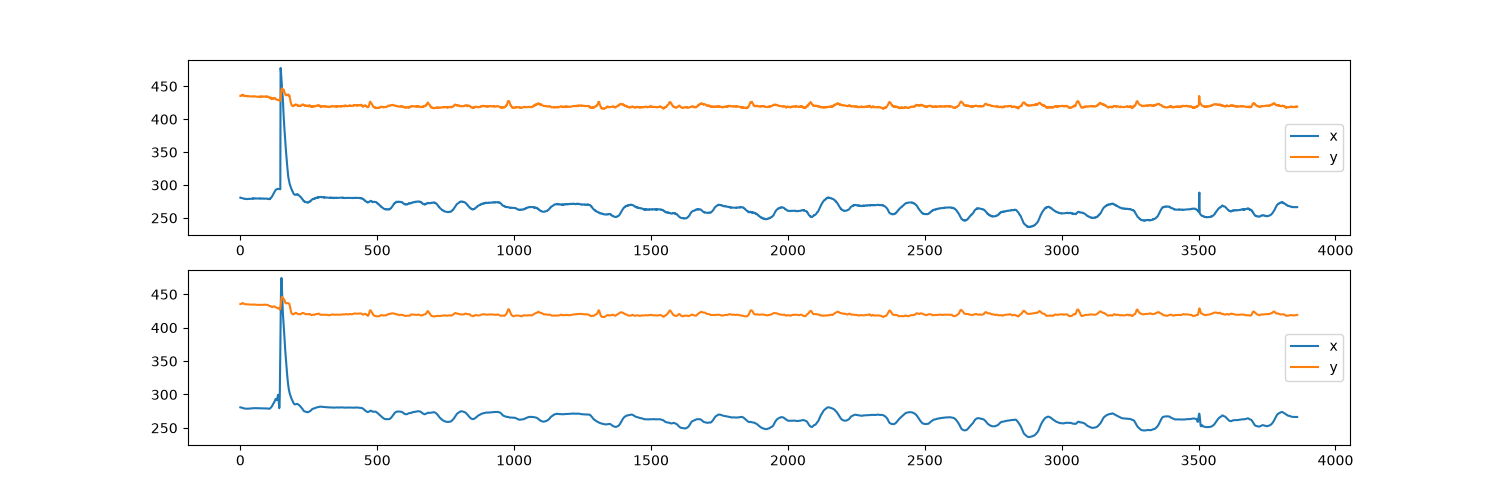

In [32]:
print(keypoints_2d.shape)
KPT_IDX = 19
plt.close('all')
fig, axs = plt.subplots(2,1, figsize=(15,5))
axs[0].plot(keypoints_2d[:,KPT_IDX,:], label=['x','y'])
axs[0].legend()

axs[1].plot(lowpassed[:,KPT_IDX,:], label=['x','y'])
axs[1].legend()

# for ax in axs:
#     ax.set_ylim([200,350])

In [7]:
import cv2
import numpy as np
import time

keypoints_vis=lowpassed

video_path = os.path.join('data',recording_name, recording_name+'_color.mp4')
cap = cv2.VideoCapture(video_path)

frame_idx = 0
while True:
    ret, frame = cap.read()
    if not ret or frame_idx >= len(keypoints_vis):
        break

    frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
    
    # Keypoints for this frame: (num_keypoints, 2)
    pts = keypoints_vis[frame_idx]

    # Draw circles
    for x, y in pts:
        if np.isfinite(x) and np.isfinite(y):
            cv2.circle(
                frame,
                (int(x), int(y)),
                3,              # radius
                (0, 0, 255),    # BGR = red
                -1              # filled
            )
    cv2.putText(frame, str(frame_idx), (40,40),cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2 )

    cv2.imshow("Pose", frame)

    # Press ESC to quit
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

    frame_idx += 1
    # time.sleep(0.075)
    time.sleep(0.03)

cap.release()
cv2.destroyAllWindows()

# Get 3D keypoints

In [7]:
import os
import json
import subprocess
import numpy as np
import pyrealsense2 as rs
from util import *

recording_name = "w1"
folder_name = os.path.join("data", recording_name)
filename_keypoints_2d = os.path.join(folder_name, recording_name+"_keypoints_2d_filtered.npy")
filename_metadata = os.path.join(folder_name, recording_name+"_metadata.json")
filename_depth = os.path.join(folder_name, recording_name+"_depth.mkv")
out_filename_keypoints_3d = os.path.join(folder_name, recording_name+"_keypoints_3d.npy")

if not os.path.exists(filename_keypoints_2d):
    raise FileNotFoundError(f'File {filename_keypoints_2d} does not exist')
if not os.path.exists(filename_metadata):
    raise FileNotFoundError(f'File {filename_metadata} does not exist')
if not os.path.exists(filename_depth):
    raise FileNotFoundError(f'File {filename_depth} does not exist')

keypoints_2d = np.load(filename_keypoints_2d)
with open(filename_metadata) as f:
    metadata = json.load(f)

print(f'keypoints_2d: {keypoints_2d.shape}')
print(f'metadata loaded: {filename_metadata}')

keypoints_2d: (3860, 27, 2)
metadata loaded: data\w1\w1_metadata.json


In [8]:
depth_scale = metadata["depth_scale_meters"]  # conversion to meters
intrinsics = create_intrinsics_object(intrinsics_dict=metadata["color_intrinsics"])

W = intrinsics.width
H = intrinsics.height
n_frames = metadata["frames"]

bytes_per_frame = W * H * 2  # uint16 = 2 bytes/pixel

ffmpeg_cmd = ["ffmpeg", "-i", filename_depth, "-f", "rawvideo", "-pix_fmt", "gray16le", "-"]
video_depth = subprocess.Popen(
    ffmpeg_cmd, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, bufsize=10**8
)

keypoints_3d = []
frame_idx = 0
while frame_idx < metadata["frames"] - 1:
    raw_frame_data = video_depth.stdout.read(bytes_per_frame)
    if len(raw_frame_data) < bytes_per_frame:
        break
    current_frame_depth_map = np.frombuffer(raw_frame_data, dtype=np.uint16).reshape(H, W)
    current_frame_depth_map = current_frame_depth_map.copy()

    current_keypoints_2d = keypoints_2d[frame_idx, :, :]

    current_keypoints_3d = []
    # NOTE: pose estimation runs in portrait, x,y must be landscape for depth
    for kpt_idx, (x_portrait, y_portrait) in enumerate(current_keypoints_2d):
        ## 90 deg clockwise rotation of the physical camera
        # x_landscape = int(round(W - 1 - y_portrait))
        # y_landscape = int(round(x_portrait))

        ## 90 deg counterclockwise
        x_landscape = int(round(y_portrait))
        y_landscape = int(round(H-1-x_portrait))

        if not (0 <= x_landscape < W and 0 <= y_landscape < H):
            current_keypoints_3d.append([np.nan, np.nan, np.nan])
            continue

        d = (
            sample_depth_patch(
                depth_map=current_frame_depth_map, x=x_landscape, y=y_landscape, radius=1
            )
            * depth_scale
        )

        if d <= 0:  # invalid/missing depth reading
            current_keypoints_3d.append([np.nan, np.nan, np.nan])
            print(f'depth less than 0: {frame_idx}, kpt: {kpt_idx}, {d}')
            continue

        # [x, y, d] = rs.rs2_deproject_pixel_to_point(
        #     intrin=intrinsics, pixel=(x_landscape, y_landscape), depth=d
        # )
        x = (x_landscape-intrinsics.ppx)* d / intrinsics.fx
        y = (y_landscape-intrinsics.ppy)*d / intrinsics.fy



        # NOTE: negative x coord so it is not upside down
        current_keypoints_3d.append([-x, -y, d])

    keypoints_3d.append(current_keypoints_3d)
    frame_idx += 1

video_depth.stdout.close()
video_depth.wait()

keypoints_3d = np.asanyarray(keypoints_3d)

# TODO: change fps to metadata fps
gapfilled_keypoints = interpolate_gaps(keypoints=keypoints_3d, fps=60, max_gap=0.25)
gapfilled_keypoints = lowpass_keypoints(keypoints=gapfilled_keypoints, fps=60, cutoff=2, order=4)
np.save(out_filename_keypoints_3d, gapfilled_keypoints)

# Transform 3D coords to global frame

## Calibration

In [9]:
import os
import json
import numpy as np
import cv2
from util import get_image_points, Pattern, stereo_labels
import matplotlib.pyplot as plt

recording_name = "w1"
folder_name = os.path.join("data", recording_name)
filename_metadata = os.path.join(folder_name, recording_name + "_metadata.json")
filename_keypoints_3d = os.path.join(folder_name, recording_name + "_keypoints_3d.npy")
filename_calibration_img = os.path.join(folder_name, "calibration_image.png")
out_filename_keypoints_3d_global = os.path.join(
    folder_name, recording_name + "_stereo.npz"
)

if not os.path.exists(filename_metadata):
    raise FileNotFoundError(f"File {filename_metadata} does not exist")
if not os.path.exists(filename_keypoints_3d):
    raise FileNotFoundError(f"File {filename_keypoints_3d} does not exist")
if not os.path.exists(filename_calibration_img):
    raise FileNotFoundError(f"File {filename_calibration_img} does not exist")

with open(filename_metadata) as f:
    metadata = json.load(f)
color_intrinsics = metadata["color_intrinsics"]

keypoints_3d = np.load(filename_keypoints_3d)
print(f"keypoints_3d: {keypoints_3d.shape}")

keypoints_3d: (3859, 27, 3)


In [10]:
pattern = Pattern(height=6, width=4, square_size=0.15)
calibration_image = cv2.imread(filename_calibration_img, cv2.IMREAD_GRAYSCALE)
image_points, debug_image = get_image_points(
    calibration_image=calibration_image, calibration_pattern=pattern
)
# show debug image
cv2.imshow("img", debug_image)
cv2.waitKey(0)
cv2.destroyAllWindows()
camera_matrix = np.array(
    [
        [color_intrinsics["fx"], 0, color_intrinsics["ppx"]],
        [0, color_intrinsics["fy"], color_intrinsics["ppy"]],
        [0, 0, 1],
    ],
    dtype=np.float64,
)
distortion_coeffs = np.array(color_intrinsics["coeffs"])
success, rvec, t_vec = cv2.solvePnP(
    objectPoints=pattern.pattern_points,
    imagePoints=image_points,
    cameraMatrix=camera_matrix,
    distCoeffs=distortion_coeffs,
    useExtrinsicGuess=False,
    flags=cv2.SOLVEPNP_ITERATIVE,
)
if success:
    R, jac = cv2.Rodrigues(rvec)

    camera_position_global_frame = (-R.T @ t_vec).ravel()

    print(f"distance: {round(np.linalg.norm(camera_position_global_frame),2)} m")


projected, _ = cv2.projectPoints(
    pattern.pattern_points,
    rvec,
    t_vec,
    camera_matrix,
    distortion_coeffs
)
error = np.linalg.norm(
    projected.reshape(-1, 2) - image_points.reshape(-1, 2),
    axis=1
)

print("mean reprojection error:", error.mean())
print("max reprojection error:", error.max())

keypoints_3d_global = keypoints_3d @ R + camera_position_global_frame
# np.save(out_filename_keypoints_3d_global, keypoints_3d_global)
with open(out_filename_keypoints_3d_global, "w"):
    np.savez(out_filename_keypoints_3d_global, labels=stereo_labels, keypoints=keypoints_3d_global)
    print(
        f"stereo keypoints saved to: {out_filename_keypoints_3d_global} with shape: {keypoints_3d_global.shape}"
    )

distance: 1.95 m
mean reprojection error: 2.4727967
max reprojection error: 5.0293083
stereo keypoints saved to: data\w1\w1_stereo.npz with shape: (3859, 27, 3)


# Draw keypoints

In [11]:
import numpy as np
import os
from util import load_keypoints_and_labels
recording_name = 'w1'
stereo_keypoints, stereo_labels = load_keypoints_and_labels(npz_data_path=os.path.join('data',recording_name,f'{recording_name}_stereo.npz'))
# qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(npz_data_path=os.path.join('data', recording_name, recording_name+'_qualisys.npz'))

loaded data from: data\w1\w1_stereo.npz with keys: ['labels', 'keypoints']


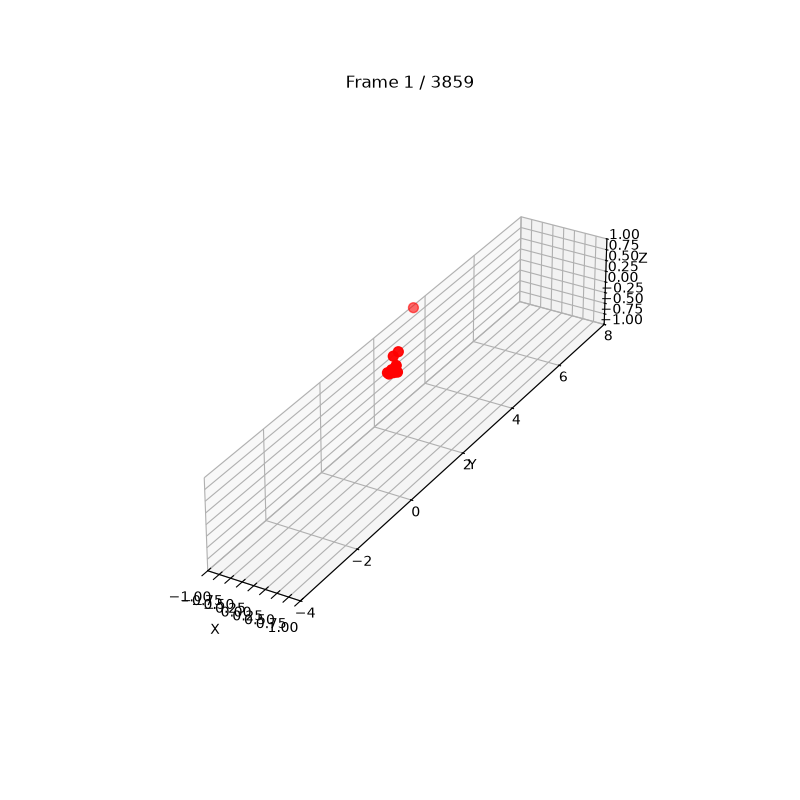

In [17]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl

frame = 0

plt.close('all')
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

keypoints = stereo_keypoints
# keypoints = qualisys_keypoints


def update():
    ax.clear()

    pts = keypoints[frame]

    # Plot all 26 keypoints
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=50, c="red")

    ax.set_title(f"Frame {frame + 1} / {len(keypoints)}") 

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    x_min, x_max = (-1,1)
    y_min, y_max = (-4,8)
    z_min, z_max = (-1,1)
    ax.set_xlim(x_min,x_max)
    ax.set_ylim(y_min,y_max)
    ax.set_zlim(z_min,z_max)
    ax.set_box_aspect([x_max-x_min, y_max-y_min, z_max-z_min])

    fig.canvas.draw_idle()


def on_key(event):
    global frame

    if event.key == "right":
        frame = min(frame + 1, len(keypoints) - 1)
        update()

    elif event.key == "left":
        frame = max(frame - 1, 0)
        update()
    elif event.key == "up":
        frame = min(frame + 30, len(keypoints) - 1)
        update()
    elif event.key == "down":
        frame = max(frame - 30, 0)
        update()

fig.canvas.mpl_connect("key_press_event", on_key)

update()
plt.show()

In [ ]:
import numpy as np
from OneEuroFilter import OneEuroFilter


def filter_keypoints(keypoints, fps):
    n_frames, n_keypoints, _ = keypoints.shape

    # One filter for each keypoint and each coordinate
    filters = [
        [OneEuroFilter(freq=fps, mincutoff=1.0, beta=0.1, dcutoff=1.0) for coordinate in range(3)]
        for keypoint in range(n_keypoints)
    ]

    filtered = np.empty_like(keypoints, dtype=float)

    for frame_idx in range(n_frames):
        timestamp = frame_idx / fps

        for kpt_idx in range(n_keypoints):
            for xyz in range(3):
                filtered[frame_idx, kpt_idx, xyz] = filters[kpt_idx][xyz].filter(keypoints[frame_idx, kpt_idx, xyz], timestamp)

    return filtered

In [ ]:
dt = 1/metadata['fps']

mid_shoulder_velocity = np.diff(mid_shoulder, axis=0) / dt
mid_shoulder_speed = np.linalg.norm(mid_shoulder_velocity, axis=1)

mid_shoulder_acceleration = np.diff(mid_shoulder, n=2, axis=0) / dt**2
mid_shoulder_acceleration_magnitude = np.linalg.norm(mid_shoulder_acceleration, axis=1)

In [ ]:
# keypoints_3d_global.shape
mid_shoulder = np.array((keypoints_3d_global[:, 5, :] + keypoints_3d_global[:, 6, :]) / 2)
mid_hips = np.array((keypoints_3d_global[:, 11, :] + keypoints_3d_global[:, 12, :]) / 2)
left_ankle = keypoints_3d_global[:, 15, :]
right_ankle = keypoints_3d_global[:, 16, :]
print(f"keypoints_3d_global: {keypoints_3d_global.shape}")
print(f"mid_shoulder: {mid_shoulder.shape}")
print(f"left_ankle: {left_ankle.shape}")
print(f"right_ankle: {right_ankle.shape}")


fig, axs = plt.subplots(nrows=4, ncols=1, figsize=(10, 10))

axs[0].plot(mid_shoulder[:, 0], label="x")
axs[0].plot(mid_shoulder[:, 1], label="y")
axs[0].plot(mid_shoulder[:, 2], label="z")

axs[0].set_title("mid_shoulder")
# axs[0].plot(mid_shoulder_velocity, label="velocity")
axs[0].plot(mid_shoulder_velocity/10, label="acceleration")
axs[0].legend()

axs[1].plot(mid_hips)
axs[1].set_title("mid_hips")

axs[2].plot(left_ankle)
axs[2].set_title("left_ankle")

axs[3].plot(right_ankle)
axs[3].set_title("right_ankle")

for ax in axs[:-1]:
    ax.set_xticks([])
    ax.grid()
plt.tight_layout()

# Qualisys preprocessing

In [13]:
import os
import pandas as pd
import numpy as np
from util import get_qualisys_metadata, format_qualisys_export, get_basename, filter_data

recording_name = "w1"
filename_qualisys_tsv = os.path.join("data", recording_name, recording_name + ".tsv")
out_filename_qualisys_keypoints = os.path.join(
    "data", recording_name, recording_name + "_qualisys.npz"
)
if not os.path.exists(filename_qualisys_tsv):
    raise FileNotFoundError(f"File {filename_qualisys_tsv} does not exits")

In [14]:
qualisys_keypoints, qualisys_labels = format_qualisys_export(input_filename=filename_qualisys_tsv)
qualisys_keypoints = filter_data(
    data=qualisys_keypoints,
    sampling_rate=100,
    filter_type="lowpass",
    cutoff=[7],
    order=4,
    gap_size=0.25,
)
qualisys_keypoints = qualisys_keypoints.transpose(2, 0, 1)

with open(out_filename_qualisys_keypoints, "w"):
    np.savez(out_filename_qualisys_keypoints, labels=qualisys_labels, keypoints=qualisys_keypoints)
    print(
        f"qualisys keypoints saved to: {out_filename_qualisys_keypoints} with shape: {qualisys_keypoints.shape}"
    )
    

qualisys keypoints saved to: data\w1\w1_qualisys.npz with shape: (6352, 12, 3)


# Compare qualisys to realsense

In [3]:
import os
import matplotlib.pyplot as plt
%matplotlib ipympl
from util import load_keypoints_and_labels, lowpass_keypoints
recording_name = 'q2'

filename_qualisys_keypoints = os.path.join('data',recording_name,recording_name+'_qualisys.npz')
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(npz_data_path=filename_qualisys_keypoints)

filename_stereo_keypoints = os.path.join('data',recording_name,recording_name+'_stereo.npz')
stereo_keypoints, stereo_labels = load_keypoints_and_labels(npz_data_path=filename_stereo_keypoints)

loaded data from: data\q2\q2_qualisys.npz with keys: ['labels', 'keypoints']
loaded data from: data\q2\q2_stereo.npz with keys: ['labels', 'keypoints']


In [ ]:
stereo_keypoints = lowpass_keypoints(keypoints=stereo_keypoints, fps=60,cutoff=2,order=4)

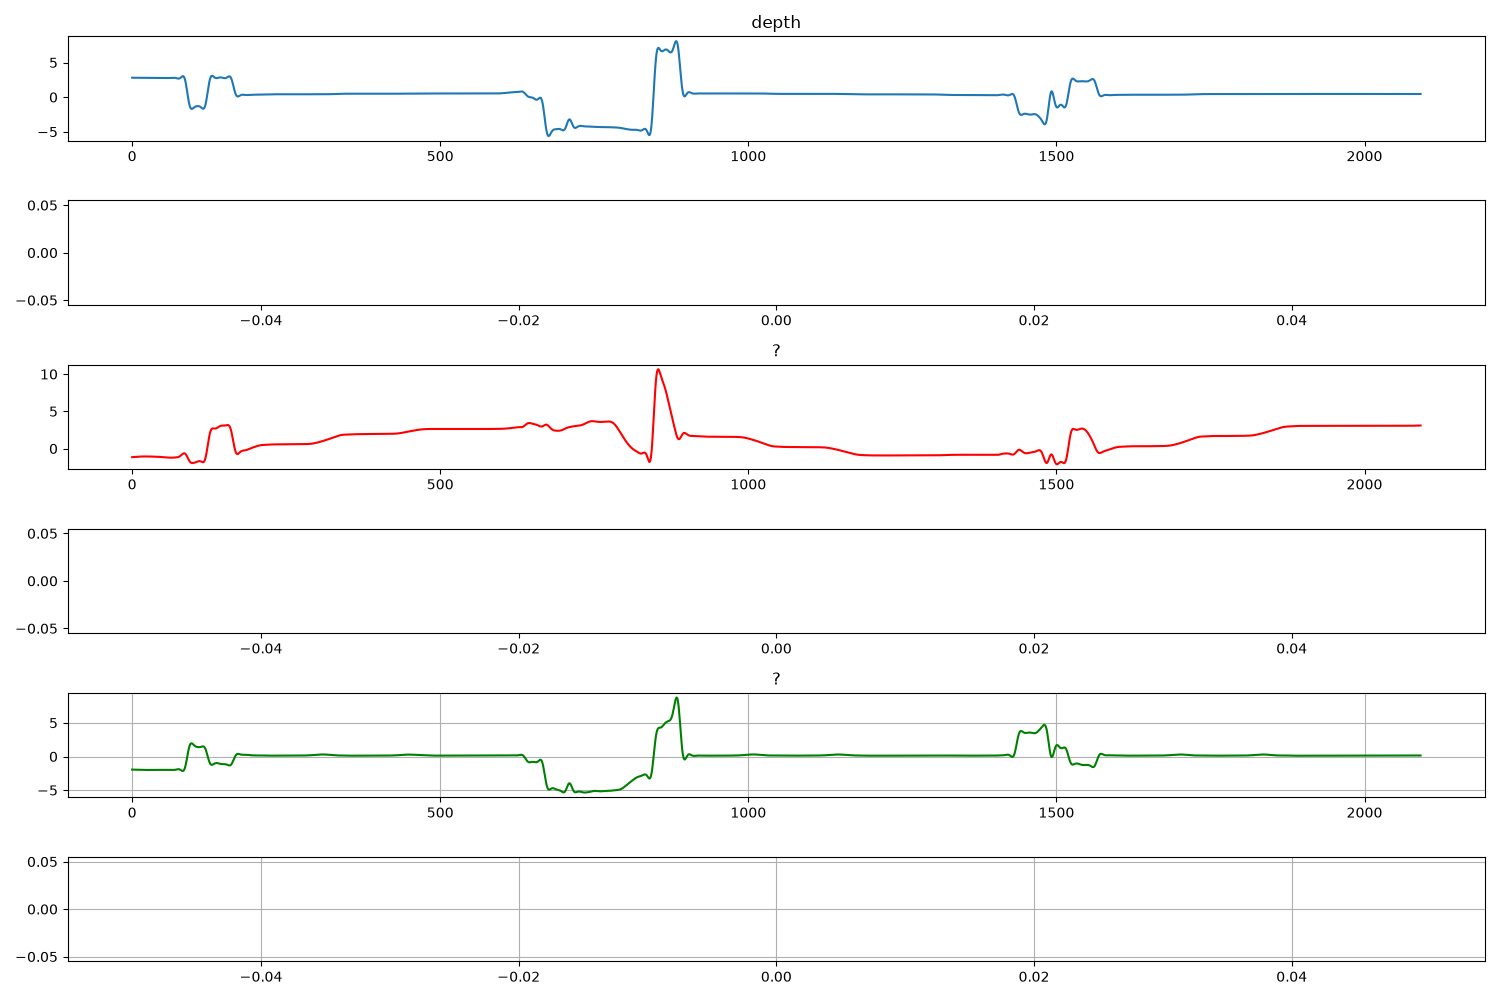

In [15]:
KPT_NAME = 'left_ankle'
stereo_cut=0
qualisys_cut = -1

plt.close('all')
fig, axs = plt.subplots(6,1, figsize=(15,10))
axs[0].set_title('depth')
axs[0].plot(qualisys_keypoints[:qualisys_cut, qualisys_labels.index(KPT_NAME),0])
axs[1].plot(stereo_keypoints[stereo_cut:,stereo_labels.index(KPT_NAME),1])
# for ax in axs[:2]:
#     ax.set_ylim([-0.5,1])
#     ax.grid()

axs[2].set_title('?')
axs[2].plot(qualisys_keypoints[:qualisys_cut, qualisys_labels.index(KPT_NAME),1],'r')
axs[3].plot(-stereo_keypoints[stereo_cut:,stereo_labels.index(KPT_NAME),0],'r')
# axs[2].set_ylim([])

axs[4].set_title('?')
axs[4].plot(qualisys_keypoints[:qualisys_cut, qualisys_labels.index(KPT_NAME),2],'g')
axs[5].plot(stereo_keypoints[stereo_cut:,stereo_labels.index(KPT_NAME),2],'g')
for ax in axs[4:]:
    # ax.set_ylim([-0.5,1])
    ax.grid()


plt.tight_layout()

# Small tests

## Draw trajectories

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

recording_name = 'q1'
# keypoints_2d = np.load(os.path.join('data',recording_name, recording_name+'_keypoints_2d.npy'))
print(keypoints_2d.shape)
KPT_IDX = 6
plt.close('all')
fig, axs = plt.subplots(3,1, figsize=(15,5))
axs[0].plot(keypoints_2d[:,KPT_IDX,:], label=['x','y'])
axs[0].legend()

In [ ]:
import cv2
import numpy as np
import time

video_path = os.path.join('data',recording_name, recording_name+'_color.mp4')

cap = cv2.VideoCapture(video_path)

frame_idx = 0

while True:
    ret, frame = cap.read()
    if not ret or frame_idx >= len(keypoints_2d):
        break

    frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
    
    # Keypoints for this frame: (num_keypoints, 2)
    pts = keypoints_2d[frame_idx]

    # Draw circles
    for x, y in pts:
        if np.isfinite(x) and np.isfinite(y):
            cv2.circle(
                frame,
                (int(x), int(y)),
                3,              # radius
                (0, 0, 255),    # BGR = red
                -1              # filled
            )

    cv2.imshow("Pose", frame)

    # Press ESC to quit
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

    frame_idx += 1
    time.sleep(0.075)

cap.release()
cv2.destroyAllWindows()

In [ ]:
ord('q')

## Compressed depth

In [ ]:
import numpy as np
import blosc2

depth = np.asarray(depth_frame.get_data(), dtype=np.uint16)

compressed = blosc2.compress(
    depth,
    typesize=2,
    clevel=3,
    filter=blosc2.Filter.SHUFFLE,
    codec=blosc2.Codec.ZSTD
)

In [ ]:
raw = blosc2.decompress(compressed)

depth_restored = np.frombuffer(
    raw,
    dtype=np.uint16
).reshape(480, 848)

In [ ]:
assert np.array_equal(depth, depth_restored)

In [ ]:
import os
import json
import time
import struct

import cv2
import numpy as np
import pyrealsense2 as rs
import zstandard as zstd


recording_name = "asdf"

WIDTH = 848
HEIGHT = 480
FPS = 60
DURATION = 5

output_dir = os.path.join("data", recording_name)
os.makedirs(output_dir, exist_ok=True)

depth_filename = os.path.join(output_dir, "depth.zst")
color_filename = os.path.join(output_dir, "color.mp4")
timestamp_filename = os.path.join(output_dir, "timestamps.npz")
metadata_filename = os.path.join(output_dir, "metadata.json")

# REALSENSE SETUP
pipeline = rs.pipeline()
config = rs.config()

config.enable_stream(rs.stream.depth, WIDTH, HEIGHT, rs.format.z16, FPS)

config.enable_stream(rs.stream.color, WIDTH, HEIGHT, rs.format.bgr8, FPS)

queue = rs.frame_queue(capacity=30, keep_frames=True)


# CHECK CONFIGURATION
if not config.can_resolve(pipeline):
    raise RuntimeError(
        f"RealSense configuration cannot be resolved: " f"{WIDTH}x{HEIGHT} @ {FPS} FPS"
    )

print("Configuration OK")


# START CAMERA
profile = pipeline.start(config, queue)

device = profile.get_device()
depth_sensor = device.first_depth_sensor()
depth_scale = depth_sensor.get_depth_scale()

print("Depth scale:", depth_scale)


# COLOR VIDEO WRITER
# mp4v is widely available with OpenCV.
# It is LOSSY.
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

video_writer = cv2.VideoWriter(color_filename, fourcc, FPS, (WIDTH, HEIGHT))
if not video_writer.isOpened():
    pipeline.stop()
    raise RuntimeError("Could not open color video writer")


# DEPTH COMPRESSOR
# Level 1 is deliberately fast.
# Increase to 3 or 5 if CPU usage/storage size permits.
compressor = zstd.ZstdCompressor(level=1)


# OPEN OUTPUT FILEs
depth_file = open(depth_filename, "wb")
timestamps = []
frame_numbers = []


start_time = time.perf_counter()
frame_count = 0

try:

    while time.perf_counter() - start_time < DURATION:

        frames = queue.wait_for_frame()
        frames = frames.as_frameset()

        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()

        if not depth_frame or not color_frame:
            continue

        depth_image = np.asanyarray(depth_frame.get_data())
        depth_image = np.asarray(depth_image, dtype=np.uint16)

        # Compress the complete depth frame.
        compressed_depth = compressor.compress(depth_image.tobytes())

        depth_file.write(struct.pack("<I", len(compressed_depth)))
        depth_file.write(compressed_depth)

        # COLOR        
        color_image = np.asanyarray(color_frame.get_data())
        video_writer.write(color_image)
        
        # TIMESTAMPS        
        timestamps.append(frames.get_timestamp())
        frame_numbers.append(frames.get_frame_number())

        frame_count += 1

        # OPTIONAL DISPLAY
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )
        display = np.hstack((color_image, depth_colormap))
        cv2.imshow("RealSense", display)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    depth_file.close()
    video_writer.release()

    cv2.destroyAllWindows()

    pipeline.stop()

# SAVE TIMESTAMPS

np.savez(
    timestamp_filename,
    timestamps=np.asarray(timestamps, dtype=np.float64),
    frame_numbers=np.asarray(frame_numbers, dtype=np.int64),
)

# SAVE METADATA

metadata = {
    "width": WIDTH,
    "height": HEIGHT,
    "fps": FPS,
    "frames": frame_count,
    "depth_format": "Z16",
    "depth_dtype": "uint16",
    "depth_compression": "zstd",
    "depth_compression_level": 1,
    "color_format": "BGR8",
    "color_container": "MP4",
    "color_codec": "mp4v",
    "depth_scale": depth_scale,
}

with open(metadata_filename, "w") as f:
    json.dump(metadata, f, indent=4)


print()
print("Recording finished")
print("Frames:", frame_count)
print("Expected:", FPS * DURATION)

print()
print("Files:")

for filename in [depth_filename, color_filename, timestamp_filename, metadata_filename]:
    size_mb = os.path.getsize(filename) / (1024**2)
    print(f"{filename}: {size_mb:.2f} MB")

## frame que test

In [ ]:
import pyrealsense2 as rs
import time

# Implement two "processing" functions, each of which
# occassionally lags and takes longer to process a frame.
def slow_processing(frame):
    n = frame.get_frame_number() 
    if n % 20 == 0:
        time.sleep(1/4)
    print(n)

def slower_processing(frame):
    n = frame.get_frame_number() 
    if n % 20 == 0:
        time.sleep(1)
    print(n)

def fast_processing(frame):
    n = frame.get_frame_number()
    print(n)

frame_numbers = {
    "fast": [],
    "slow": [],
    "slow_que": [],
    "slower": [],
    "slower_que": [],
}

try:

    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(rs.stream.depth, 640, 480, rs.format.z16, 30)
    config.enable_stream(rs.stream.color, 640, 480, rs.format.bgr8, 30)



    # FAST
    print('Fast callback')
    pipeline.start(config)
    start = time.time()
    while time.time() - start < 5:
        frames = pipeline.wait_for_frames()
        frame_numbers['fast'].append(frames.get_frame_number())
        fast_processing(frames)
    pipeline.stop()


    # SLOW
    # Start streaming to the slow processing function.
    # This stream will lag, causing the occasional frame drop.
    print("Slow callback")
    pipeline.start(config)
    start = time.time()
    while time.time() - start < 5:
        frames = pipeline.wait_for_frames()
        frame_numbers['slow'].append(frames.get_frame_number())
        slow_processing(frames)
    pipeline.stop()

    # SLOW + QUE
    # Start streaming to the the slow processing function by way of a frame queue.
    # This stream will occasionally hiccup, but the frame_queue will prevent frame loss.
    print("Slow callback + queue")
    queue = rs.frame_queue(50)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slow_que'].append(frames.get_frame_number())
        slow_processing(frames)
    pipeline.stop()

    # SLOWER
    # Start streaming to the the slower processing function by way of a frame queue.
    # This stream will drop frames because the delays are long enough that the backed up
    # frames use the entire internal frame pool preventing the SDK from creating more frames.
    print("Slower callback + queue")
    queue = rs.frame_queue(50)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slower'].append(frames.get_frame_number())
        slower_processing(frames)
    pipeline.stop()

    # SLOWER + QUE
    # Start streaming to the slower processing function by way of a keeping frame queue.
    # This stream will no longer drop frames because the frame queue tells the SDK
    # to remove the frames it holds from the internal frame queue, allowing the SDK to
    # allocate space for and create more frames .
    print("Slower callback + keeping queue")
    queue = rs.frame_queue(capacity=200, keep_frames=True)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slower_que'].append(frames.get_frame_number())
        slower_processing(frames)
    pipeline.stop()

except Exception as e:
    print(e)
except:
    print("A different Error")
else:
    print("Done")

for key, value in frame_numbers.items():
    print(key, len(value))

In [ ]:
# type(frames)
frames.as_frameset()

In [ ]:
help(rs.composite_frame)

In [ ]:
for ind, frame in enumerate(frame_numbers['slower_que'],1):
    print(ind, frame)

In [ ]:
help(rs.frame_queue)